# Feature selection and RUL modelling on NASA C-MAPSS
**FD002 only | cases N, AF and DF | window L = 50 | Random Forest and XGBoost**

This notebook compares four feature-space sizes:
- Top 60 features
- Top 100 features
- Top 150 features
- All features remaining after zero-variance removal

Workflow:
1. Load the FD002 C-MAPSS subset.
2. Extract the same nine window statistics per sensor.
3. Remove exactly zero-variance extracted features, using training data only inside each CV fold.
4. Rank the remaining features using the same combined ranking: absolute Spearman correlation, mutual information, and Random Forest importance.
5. Train Random Forest and XGBoost with the existing fixed hyperparameters.
6. Evaluate using the existing five-fold engine-wise split and official test set.

**This notebook is configured specifically for FD002 and automatically runs all three preprocessing cases: N, AF and DF.**


## 1. Libraries

In [1]:
import os, time, subprocess, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


## 2. Settings

In [2]:
QUICK = os.environ.get("CMAPSS_QUICK", "0") == "1"  # QUICK=1 is only for a short pipeline check
DATASET = "FD002"  # This notebook runs FD002 only.
if DATASET != "FD002":
    raise ValueError("This notebook is configured for FD002 only.")

DATA_DIR = os.environ.get(
    "CMAPSS_DIR",
    "/kaggle/input/datasets/tanmoypauldiat/cmapps-fd001-and-fd002"
)
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs_feature_selection"
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42
L = 50
RUL_CAP = 125
N_FOLDS = 5
TRAIN_STRIDE = 4
MIN_EVAL_CYCLE = 50

# FD002 has multiple operating conditions: run all three cases.
CASES = ["N", "AF", "DF"]

# Requested feature-space sizes. ALL means every non-zero-variance feature.
FEATURE_BUDGETS = [20, 40, 60, 100, 150, "ALL"]

# Feature-ranking settings (unchanged from the previous notebook).
MI_ROWS = 5000
SEL_TREES = 100

# Model settings (same fixed RF/XGBoost configuration as before).
if QUICK:
    TRAIN_STRIDE, MI_ROWS, SEL_TREES = 8, 1500, 30

STATS = ["mean", "std", "min", "max", "median", "slope",
         "last_minus_first", "std_diff", "mean_abs_diff"]

print("dataset:", DATASET, "| cases:", CASES, "| feature budgets:", FEATURE_BUDGETS,
      "| QUICK:", QUICK)


dataset: FD002 | cases: ['N', 'AF', 'DF'] | feature budgets: [20, 40, 60, 100, 150, 'ALL'] | QUICK: False


## 3. Load FD002 data


In [3]:
def add_rul(df):
    df = df.sort_values(["unit_id", "cycle"]).reset_index(drop=True)
    df["RUL"] = df.groupby("unit_id")["cycle"].transform("max") - df["cycle"]
    df["y"] = df["RUL"].clip(upper=RUL_CAP)
    return df

train = add_rul(pd.read_csv(f"{DATA_DIR}/train_{DATASET}.csv"))
test = pd.read_csv(f"{DATA_DIR}/test_{DATASET}.csv").sort_values(
    ["unit_id", "cycle"]
).reset_index(drop=True)

rul_raw = pd.read_csv(
    f"{DATA_DIR}/RUL_{DATASET}.csv", header=None
).apply(pd.to_numeric, errors="coerce").dropna().iloc[:, 0].values

# Retain compatibility with RUL files that contain an initial header/index-like value.
if len(rul_raw) == test.unit_id.nunique() + 1:
    rul_raw = rul_raw[1:]
if len(rul_raw) != test.unit_id.nunique():
    raise ValueError(
        f"RUL label count ({len(rul_raw)}) does not match the number of test engines "
        f"({test.unit_id.nunique()}). Check RUL_{DATASET}.csv."
    )
y_test = np.minimum(rul_raw, RUL_CAP).astype(float)

# Keep all sensor columns here. Zero-variance filtering is applied to the
# extracted window features later, and is fitted separately inside each fold.
sensors = [c for c in train.columns if c.startswith("sensor")]
settings = [
    c for c in train.columns
    if c not in ("unit_id", "cycle", "RUL", "y") and not c.startswith("sensor")
]
N_CONDITIONS = 6 if DATASET == "FD002" else 1
groups = train.groupby("unit_id").indices
test_groups = test.groupby("unit_id").indices
FEATURE_NAMES = [f"{s}__{st}" for st in STATS for s in sensors]

print(
    f"{DATASET}: {train.unit_id.nunique()} training engines ({len(train)} rows), "
    f"{test.unit_id.nunique()} test engines ({len(test)} rows)"
)
print(
    f"{len(sensors)} sensors, {len(settings)} settings, {N_CONDITIONS} operating "
    f"condition(s) -> {len(FEATURE_NAMES)} extracted features per window"
)
print("Test engines with fewer than", L, "cycles:",
      int((test.groupby("unit_id").size() < L).sum()))
display(train.head(3))


FD002: 260 training engines (53759 rows), 259 test engines (33991 rows)
21 sensors, 3 settings, 6 operating condition(s) -> 189 extracted features per window
Test engines with fewer than 50 cycles: 24


,unit_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL,y
0,1,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,8.00,194.64,2222.65,8341.91,1.02,42.02,183.06,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071,148,125
1,1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,5.71,138.51,2211.57,8303.96,1.02,42.20,130.42,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665,147,125
2,1,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,9.02,175.71,1915.11,8001.42,0.94,36.69,164.22,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723,146,125


## 4. Helper functions
Short and commented. **Scaler:** learns a mean and spread per sensor (one set for the whole data, or one set per operating condition found by KMeans on the settings). **Windows:** the last 50 cycles up to cycle t, turned into 9 numbers per sensor.

In [4]:
class Scaler:
    # k = 1: one overall mean/spread.  k = 6: one mean/spread for each operating condition.
    def __init__(self, k): self.k = k
    def condition(self, df):
        if self.k == 1: return np.zeros(len(df), int)
        S = (df[settings].values - self.s_mu) / self.s_sd
        return ((S[:, None, :] - self.centers[None]) ** 2).sum(2).argmin(1)       # nearest cluster centre
    def fit(self, df):
        if self.k > 1:
            S = df[settings].values; self.s_mu, self.s_sd = S.mean(0), S.std(0) + 1e-9
            self.centers = KMeans(self.k, n_init=10, random_state=SEED).fit((S - self.s_mu) / self.s_sd).cluster_centers_
        reg, X = self.condition(df), df[sensors].values
        self.mu, self.sd = np.zeros((self.k, len(sensors))), np.ones((self.k, len(sensors)))
        for r in range(self.k):
            m = reg == r; s = X[m].std(0)
            self.mu[r], self.sd[r] = X[m].mean(0), np.where(s < 1e-9, 1.0, s)
        return self
    def transform(self, df):
        reg = self.condition(df); return (df[sensors].values - self.mu[reg]) / self.sd[reg]

def raw_changes(df):
    # change from the previous cycle of the same engine, from the raw readings
    X = df[sensors].values; d = np.zeros_like(X); d[1:] = X[1:] - X[:-1]
    d[np.r_[True, df.unit_id.values[1:] != df.unit_id.values[:-1]]] = 0
    return d

def prepare(case, df, glob, cond):
    # returns (readings used for level features, scaled changes or None)
    if case == "N":  return glob.transform(df), None
    if case == "AF": return cond.transform(df), None
    if case == "DF": return cond.transform(df), raw_changes(df) / cond.sd[cond.condition(df)]

def nine_features(Wl, Wt):
    # Wl, Wt: (windows, sensors, L).  Wl -> levels.  Wt -> slope and change features.
    t = np.arange(L) - (L - 1) / 2; dW = np.diff(Wt, axis=2)
    return np.concatenate([Wl.mean(2), Wl.std(2), Wl.min(2), Wl.max(2), np.median(Wl, 2),
                           (Wt * t).sum(2) / (t ** 2).sum(), Wt[:, :, -1] - Wt[:, :, 0], dW.std(2), np.abs(dW).mean(2)], axis=1)

def path_from_changes(Wd):
    # DF: add up the scaled changes inside the window to get a path that starts at 0
    return np.concatenate([np.zeros_like(Wd[:, :, :1]), np.cumsum(Wd, axis=2)], axis=2)

def make_windows(levels, changes, units, start, stride):
    # one row per window that ends at cycle t >= start.  Only cycles up to t are used.
    feats, rows = [], []
    for u in units:
        idx = groups[u]; ends = np.arange(max(L, start) - 1, len(idx), stride)
        if len(ends) == 0: continue
        sel = ends - (L - 1)
        Wl = sliding_window_view(levels[idx], L, axis=0)[sel]
        Wt = Wl if changes is None else path_from_changes(sliding_window_view(changes[idx], L, axis=0)[sel][:, :, 1:])
        feats.append(nine_features(Wl, Wt)); rows.append(idx[ends])
    rows = np.concatenate(rows); return pd.DataFrame(np.vstack(feats), columns=FEATURE_NAMES), rows

def make_test_windows(levels, changes):
    # one row per test engine: its last 50 cycles. A shorter engine is padded by repeating its first reading.
    feats = []
    for u, idx in test_groups.items():
        a = levels[idx]
        if len(a) < L: a = np.vstack([np.repeat(a[:1], L - len(a), 0), a])
        Wl = a[-L:].T[None]
        if changes is None: Wt = Wl
        else:
            d = changes[idx]
            if len(d) < L: d = np.vstack([np.zeros((L - len(d), d.shape[1])), d])
            Wt = path_from_changes(d[-L:].T[None][:, :, 1:])
        feats.append(nine_features(Wl, Wt)[0])
    return pd.DataFrame(np.array(feats), columns=FEATURE_NAMES)

def nasa_score(y, p):
    d = p - y; return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))
def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(p) - np.asarray(y)) ** 2)))

## 5. Feature extraction in the three cases
For exploring, the scaling is fitted on all training engines. (When we train and validate in section 9, it is fitted again inside every fold, so no validation engine is used.) Each cell gives one table: one row per window, 9 features per sensor, plus the target `y`.

In [5]:
glob_all = Scaler(1).fit(train); cond_all = Scaler(N_CONDITIONS).fit(train)       # EDA only: fitted on all training engines
units_all = np.array(sorted(groups)); FEAT, META = {}, {}

def extract(case):
    levels, changes = prepare(case, train, glob_all, cond_all)
    X, rows = make_windows(levels, changes, units_all, start=L, stride=TRAIN_STRIDE)
    FEAT[case] = X; META[case] = train.iloc[rows][["unit_id", "cycle", "RUL", "y"]].reset_index(drop=True)
    print(f"case {case}: {X.shape[0]} windows x {X.shape[1]} features | all finite: {bool(np.isfinite(X.values).all())}")

### Case N: no adjustment (one overall scaling)

In [6]:
extract("N") if "N" in CASES else print('skipped (identical to AF on FD001)')

case N: 10353 windows x 189 features | all finite: True


### Case AF: adjust first, then extract

In [7]:
extract("AF")
display(FEAT["AF"].iloc[:3, :6])

case AF: 10353 windows x 189 features | all finite: True


,sensor_1__mean,sensor_2__mean,sensor_3__mean,sensor_4__mean,sensor_5__mean,sensor_6__mean
0,2.102524e-11,-0.167244,-0.192419,-0.092073,-4.231193e-13,-0.556732
1,2.250431e-11,-0.158100,-0.145573,-0.101591,-3.563017e-13,-0.500335
2,2.570118e-11,-0.223591,-0.125962,-0.063982,-3.016609e-13,-0.522632


### Case DF: difference first, then adjust

In [8]:
extract("DF") if "DF" in CASES else print('skipped (identical to AF on FD001)')

case DF: 10353 windows x 189 features | all finite: True


## 6. EDA 1: what do the features look like?
Static features (no variation) cannot help any model. We count them, and look at how many sensors are mostly noise.

,windows,extracted_features,zero_variance_features,remaining_features,zero_variance_share
case,,,,,
N,10353,189,0,189,0.0%
AF,10353,189,14,175,7.4%
DF,10353,189,10,179,5.3%


N: zero-variance extracted features (0): []
AF: zero-variance extracted features (14): ['sensor_18__mean', 'sensor_18__std', 'sensor_1__min', 'sensor_5__min', 'sensor_18__min', 'sensor_19__min', 'sensor_18__max', 'sensor_19__max', 'sensor_18__median', 'sensor_19__median', 'sensor_18__slope', 'sensor_18__last_minus_first', 'sensor_18__std_diff', 'sensor_18__mean_abs_diff']
DF: zero-variance extracted features (10): ['sensor_18__mean', 'sensor_18__std', 'sensor_1__min', 'sensor_5__min', 'sensor_18__min', 'sensor_19__min', 'sensor_18__max', 'sensor_19__max', 'sensor_18__median', 'sensor_19__median']


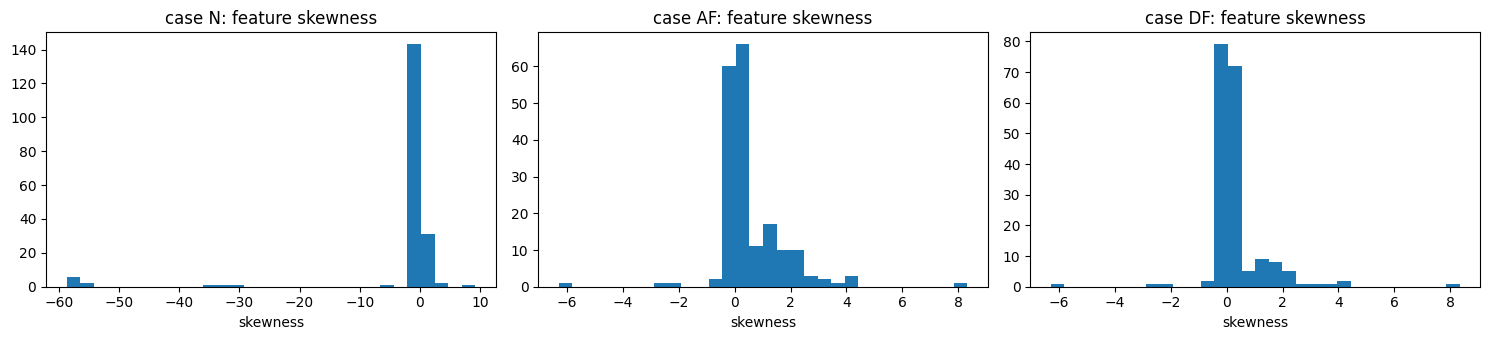

In [9]:
# This is a descriptive, full-training-set check only.
# During cross-validation, the actual zero-variance filter is refitted on Xtr
# separately inside each fold to avoid using validation data.
rows = []
for c in CASES:
    X = FEAT[c]
    variances = X.var(axis=0, ddof=0)
    n_zero = int((variances == 0).sum())
    rows.append({
        "case": c,
        "windows": len(X),
        "extracted_features": X.shape[1],
        "zero_variance_features": n_zero,
        "remaining_features": int((variances > 0).sum()),
        "zero_variance_share": f"{n_zero / X.shape[1]:.1%}"
    })
display(pd.DataFrame(rows).set_index("case"))

for c in CASES:
    zero_cols = FEAT[c].columns[FEAT[c].var(axis=0, ddof=0) == 0].tolist()
    print(f"{c}: zero-variance extracted features ({len(zero_cols)}):", zero_cols)

fig, ax = plt.subplots(1, len(CASES), figsize=(5 * len(CASES), 3.5), squeeze=False)
for a, c in zip(ax[0], CASES):
    sk = FEAT[c].skew().dropna()
    a.hist(sk, bins=30)
    a.set_title(f"case {c}: feature skewness")
    a.set_xlabel("skewness")
plt.tight_layout()
plt.show()


## 7. EDA 2: how does each feature relate to RUL?
**Spearman correlation** with RUL measures whether a feature moves steadily as RUL falls (+1 or -1 is a perfect steady relationship, 0 is none). The heat maps show every sensor and statistic for each case.

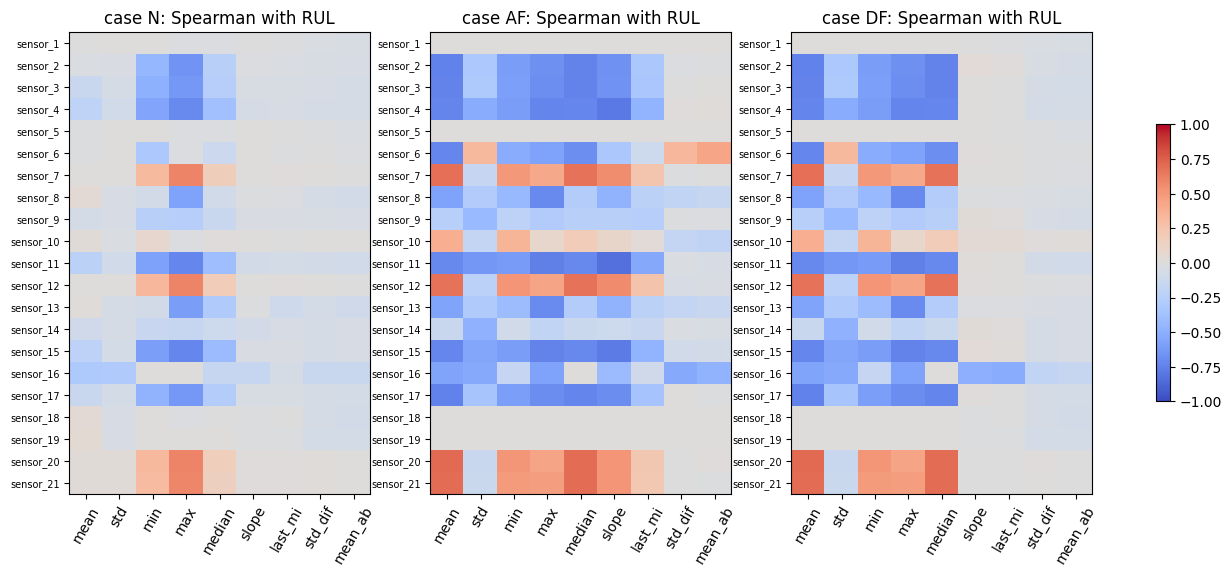

Average |Spearman| by statistic (higher = that kind of feature tracks RUL better):


,N,AF,DF
mean,0.081,0.493,0.493
std,0.053,0.279,0.279
min,0.255,0.373,0.373
max,0.386,0.437,0.437
median,0.173,0.424,0.424
slope,0.030,0.415,0.038
last_minus_first,0.029,0.215,0.035
std_diff,0.044,0.079,0.045
mean_abs_diff,0.049,0.081,0.049


In [10]:
RHO = {c: FEAT[c].apply(lambda col: spearmanr(col.values, META[c].y.values)[0] if col.std() > 1e-8 else 0.0).fillna(0.0) for c in CASES}
fig, ax = plt.subplots(1, len(CASES), figsize=(5.5 * len(CASES), 6), squeeze=False)
for a, c in zip(ax[0], CASES):
    M = pd.DataFrame({st: [RHO[c][f"{s}__{st}"] for s in sensors] for st in STATS}, index=sensors)
    im = a.imshow(M.values, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1); a.grid(False)
    a.set_xticks(range(len(STATS))); a.set_xticklabels([s[:7] for s in STATS], rotation=60); a.set_yticks(range(len(sensors))); a.set_yticklabels(sensors, fontsize=7); a.set_title(f"case {c}: Spearman with RUL")
plt.colorbar(im, ax=ax[0], shrink=.6); plt.show()
print("Average |Spearman| by statistic (higher = that kind of feature tracks RUL better):")
display(pd.DataFrame({c: RHO[c].abs().groupby([n.split("__")[1] for n in RHO[c].index]).mean() for c in CASES}).reindex(STATS).round(3))

## 8. Feature ranking after zero-variance removal

For each training fold, we first remove every extracted feature whose variance is exactly zero in that fold's training windows. We then rank the remaining features using the same three methods:

1. **Absolute Spearman correlation** with RUL.
2. **Mutual information** with RUL.
3. **Random Forest impurity importance**.

Each method is converted to a percentile rank, and the three ranks are averaged. The top 60, 100 or 150 features are then evaluated. `ALL` means all non-zero-variance features, without a feature-count cap.

For this experiment, we do **not** apply the old 0.95 correlation-pruning step: it could return fewer than the requested 60, 100 or 150 features. The requested feature counts therefore remain interpretable. The zero-variance filter and feature ranking are fitted using training engines only inside each fold.


In [11]:
def rank_features(X, y):
    # Exact zero-variance filter: fit on the training partition only.
    variances = X.var(axis=0, ddof=0)
    X_nz = X.loc[:, variances > 0].copy()

    if X_nz.shape[1] == 0:
        raise ValueError("All extracted features have zero variance in this training fold.")

    y = np.asarray(y)
    rho = X_nz.apply(
        lambda col: abs(spearmanr(col.to_numpy(), y)[0])
    ).fillna(0.0)

    rows = np.random.default_rng(SEED).choice(
        len(X_nz), min(len(X_nz), MI_ROWS), replace=False
    )
    mi = pd.Series(
        mutual_info_regression(
            X_nz.to_numpy()[rows], y[rows],
            n_neighbors=3, random_state=SEED
        ),
        index=X_nz.columns
    )

    forest = RandomForestRegressor(
        n_estimators=SEL_TREES,
        min_samples_leaf=5,
        max_features=0.33,
        n_jobs=-1,
        random_state=SEED
    ).fit(X_nz.to_numpy(), y)

    imp = pd.Series(forest.feature_importances_, index=X_nz.columns)
    score = (
        rho.rank(pct=True) +
        mi.rank(pct=True) +
        imp.rank(pct=True)
    ) / 3

    ranking = pd.DataFrame({
        "variance": variances.loc[X_nz.columns],
        "spearman": rho,
        "mutual_info": mi,
        "rf_importance": imp,
        "score": score
    }).sort_values("score", ascending=False)

    return X_nz.columns.tolist(), ranking, int((variances == 0).sum())


def choose_features(X, y, budget):
    nonzero_features, ranking, n_zero = rank_features(X, y)

    if budget == "ALL":
        selected = nonzero_features
    else:
        selected = ranking.index[:min(int(budget), len(ranking))].tolist()

    return selected, ranking, n_zero


# Full-data ranking is for descriptive EDA/export only.
# CV model fitting below recomputes the ranking within each training fold.
RANKINGS = {}
for c in CASES:
    selected, RANKINGS[c], n_zero = choose_features(FEAT[c], META[c].y.values, "ALL")
    print(
        f"case {c}: {n_zero} zero-variance features removed; "
        f"{len(selected)} features remain"
    )
    print(f"case {c}: top 15 features by combined rank")
    display(RANKINGS[c].head(15).round(5))


case N: 0 zero-variance features removed; 189 features remain
case N: top 15 features by combined rank


,variance,spearman,mutual_info,rf_importance,score
sensor_11__max,0.00473,0.72172,0.47013,0.21031,0.99647
sensor_15__max,0.00225,0.72062,0.53200,0.18118,0.99647
sensor_4__max,0.00396,0.70824,0.51761,0.12975,0.99118
sensor_3__max,0.00199,0.62974,0.40381,0.03394,0.97531
sensor_13__max,0.00000,0.60746,0.32180,0.08188,0.97002
sensor_2__max,0.00036,0.65132,0.31697,0.05637,0.97002
sensor_17__max,0.00202,0.62543,0.31998,0.01240,0.96120
sensor_15__min,0.00119,0.59739,0.32738,0.00836,0.95238
sensor_21__max,0.00047,0.58591,0.32388,0.01045,0.95238
sensor_7__max,0.00036,0.59544,0.26247,0.00935,0.93474


case AF: 14 zero-variance features removed; 175 features remain
case AF: top 15 features by combined rank


,variance,spearman,mutual_info,rf_importance,score
sensor_11__slope,0.00011,0.83339,0.66789,0.30178,1.00000
sensor_4__slope,0.00012,0.78481,0.59056,0.12587,0.98667
sensor_15__slope,0.00011,0.77924,0.53640,0.14872,0.98476
sensor_11__max,0.67693,0.75450,0.60203,0.05453,0.98286
sensor_15__max,0.62688,0.73657,0.60565,0.04178,0.97524
sensor_4__max,0.58428,0.72818,0.60770,0.01364,0.95619
sensor_2__mean,0.30040,0.74359,0.51062,0.01183,0.95619
sensor_4__mean,0.41291,0.72887,0.50323,0.01783,0.94476
sensor_2__median,0.30869,0.73599,0.52071,0.00559,0.94286
sensor_13__max,0.83791,0.70279,0.49280,0.04048,0.93143


case DF: 10 zero-variance features removed; 179 features remain
case DF: top 15 features by combined rank


,variance,spearman,mutual_info,rf_importance,score
sensor_11__max,0.67693,0.75450,0.61034,0.20807,0.99814
sensor_15__max,0.62688,0.73657,0.60536,0.07569,0.98324
sensor_17__mean,0.30882,0.74304,0.50894,0.05168,0.97952
sensor_2__mean,0.30040,0.74359,0.50315,0.02150,0.97393
sensor_4__max,0.58428,0.72818,0.61293,0.02950,0.97207
sensor_4__mean,0.41291,0.72887,0.50139,0.02140,0.95717
sensor_2__median,0.30869,0.73599,0.51879,0.00841,0.95345
sensor_13__max,0.83791,0.70279,0.50015,0.11201,0.95158
sensor_3__mean,0.28733,0.74060,0.47332,0.01883,0.94786
sensor_8__max,0.82763,0.70334,0.47632,0.08630,0.94227


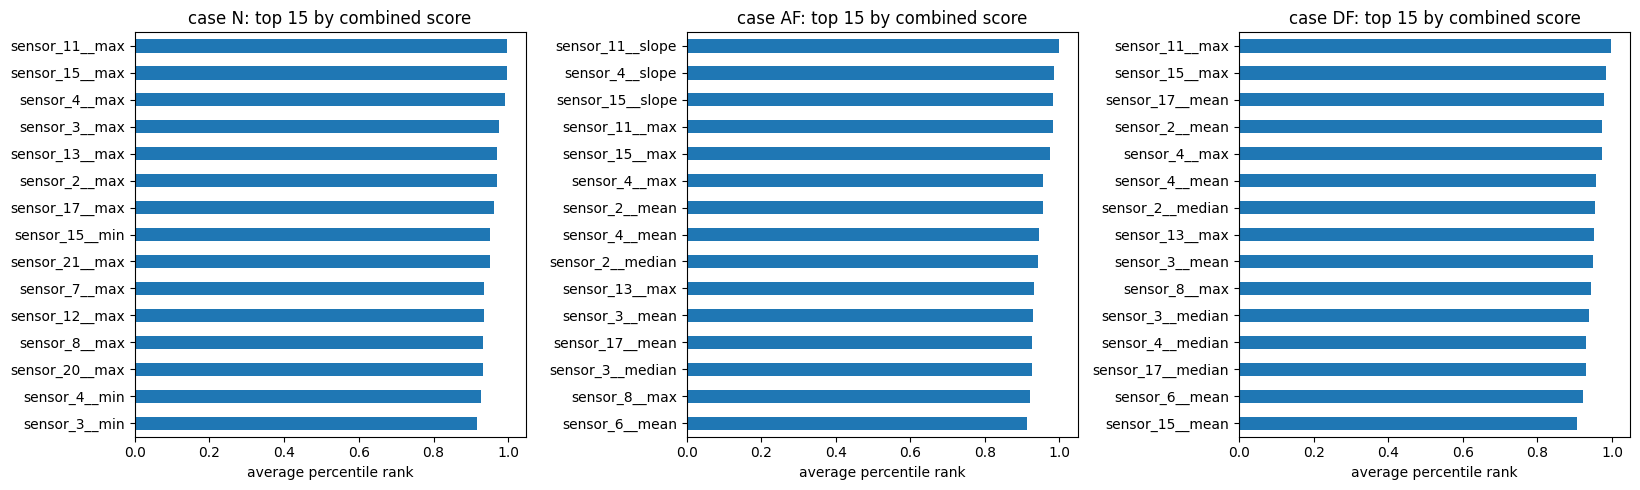

Feature-statistic counts among the top 150 (or all remaining features if fewer):


,N,AF,DF
mean,17,19,20
std,19,19,20
min,16,16,17
max,14,17,17
median,17,16,17
slope,15,17,17
last_minus_first,16,16,5
std_diff,17,15,19
mean_abs_diff,19,15,18


Top sensors by number of features in the top 150:


,N,AF,DF
sensor_1,5,4,5
sensor_10,7,8,9
sensor_11,9,9,8
sensor_12,6,9,8
sensor_13,9,9,9
sensor_14,9,8,8
sensor_15,9,9,8
sensor_16,7,7,9
sensor_17,9,8,7
sensor_18,5,0,3


In [12]:
fig, ax = plt.subplots(1, len(CASES), figsize=(5.5 * len(CASES), 5), squeeze=False)
for a, c in zip(ax[0], CASES):
    RANKINGS[c].head(15)["score"][::-1].plot.barh(ax=a)
    a.set_title(f"case {c}: top 15 by combined score")
    a.set_xlabel("average percentile rank")
plt.tight_layout()
plt.show()

print("Feature-statistic counts among the top 150 (or all remaining features if fewer):")
display(pd.DataFrame({
    c: pd.Series([f.split("__")[1] for f in RANKINGS[c].head(150).index]).value_counts()
    for c in CASES
}).reindex(STATS).fillna(0).astype(int))

print("Top sensors by number of features in the top 150:")
display(pd.DataFrame({
    c: pd.Series([f.split("__")[0] for f in RANKINGS[c].head(150).index]).value_counts()
    for c in CASES
}).fillna(0).astype(int))


## 9. Models and fixed hyperparameters

Only Random Forest and XGBoost are included, consistent with the current project scope. The model hyperparameters are held fixed across feature budgets so the experiment isolates the effect of feature-space size. Hyperparameter tuning should be conducted after this comparison.


In [13]:
def gpu_available():
    try:
        return subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
    except Exception:
        return False

USE_GPU = gpu_available()
if QUICK:
    RF_TREES, XGB_TREES = 30, 60
else:
    RF_TREES, XGB_TREES = 150, 300

MODELS = {
    "RF": lambda: RandomForestRegressor(
        n_estimators=RF_TREES,
        min_samples_leaf=5,
        max_features=0.33,
        n_jobs=-1,
        random_state=SEED
    ),
    "XGB": lambda: XGBRegressor(
        n_estimators=XGB_TREES,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        device="cuda" if USE_GPU else "cpu",
        n_jobs=-1,
        random_state=SEED
    )
}

def make_folds(units, seed=SEED):
    # Same deterministic engine-wise fold assignment as the earlier notebook.
    u = np.array(sorted(units))
    rng = np.random.default_rng(seed)
    rng.shuffle(u)
    return {int(engine): i % N_FOLDS for i, engine in enumerate(u)}

print("RF trees:", RF_TREES, "| XGB trees:", XGB_TREES, "| GPU:", USE_GPU)


RF trees: 150 | XGB trees: 300 | GPU: False


## 10. Train, validate and test each feature budget for FD002

The notebook runs all three FD002 preprocessing cases: N, AF and DF. For each case, it evaluates 60, 100, 150 and ALL non-zero-variance features using Random Forest and XGBoost.

For every five-fold engine-wise split, preprocessing, zero-variance filtering and feature ranking are fitted using training engines only. The existing validation protocol is retained: all validation windows from cycle 50 onward. The official test evaluation uses one final window per test engine.


In [14]:
RESULTS = {}
FOLD_RESULTS = []
FINAL_FEATURES = {}
FINAL_RANKINGS = {}

def run_case(case):
    t0 = time.time()
    unit_arr = train.unit_id.values
    y_all = train.y.values

    fold_of = make_folds(units_all)
    fold_arr = np.array([fold_of[u] for u in units_all])

    for fold in range(N_FOLDS):
        tr_u = units_all[fold_arr != fold]
        va_u = units_all[fold_arr == fold]
        d_tr = train[np.isin(unit_arr, tr_u)]

        # Preprocessing is fitted only on the training engines of this fold.
        glob = Scaler(1).fit(d_tr)
        cond = Scaler(N_CONDITIONS).fit(d_tr)
        levels, changes = prepare(case, train, glob, cond)

        Xtr, r_tr = make_windows(
            levels, changes, tr_u, start=L, stride=TRAIN_STRIDE
        )
        Xva, r_va = make_windows(
            levels, changes, va_u, start=MIN_EVAL_CYCLE, stride=1
        )

        # Zero-variance filtering and ranking see training windows only.
        for budget in FEATURE_BUDGETS:
            keep, ranking, n_zero = choose_features(Xtr, y_all[r_tr], budget)

            for model_name, make_model in MODELS.items():
                model = make_model()
                model.fit(Xtr[keep].to_numpy(), y_all[r_tr])

                train_pred = np.clip(
                    model.predict(Xtr[keep].to_numpy()), 0, RUL_CAP
                )
                val_pred = np.clip(
                    model.predict(Xva[keep].to_numpy()), 0, RUL_CAP
                )

                FOLD_RESULTS.append({
                    "dataset": DATASET,
                    "case": case,
                    "budget": str(budget),
                    "model": model_name,
                    "fold": fold + 1,
                    "n_features": len(keep),
                    "zero_variance_removed": n_zero,
                    "train_rmse": rmse(y_all[r_tr], train_pred),
                    "val_rmse": rmse(y_all[r_va], val_pred)
                })

        print(
            f"[{DATASET} | {case}] fold {fold + 1}/{N_FOLDS} completed "
            f"({time.time() - t0:.0f}s)"
        )

    # Summarise the five validation folds.
    F = pd.DataFrame([
        row for row in FOLD_RESULTS
        if row["dataset"] == DATASET and row["case"] == case
    ])
    print(f"\n=== {DATASET} | case {case}: validation RMSE by fold ===")
    display(
        F.pivot_table(
            index="fold", columns=["budget", "model"], values="val_rmse"
        ).round(2)
    )

    # Final fit on all training engines, followed by official test evaluation.
    glob = Scaler(1).fit(train)
    cond = Scaler(N_CONDITIONS).fit(train)
    levels, changes = prepare(case, train, glob, cond)

    Xtr, r_tr = make_windows(
        levels, changes, units_all, start=L, stride=TRAIN_STRIDE
    )
    lev_te, chg_te = prepare(case, test, glob, cond)
    Xte = make_test_windows(lev_te, chg_te)

    for budget in FEATURE_BUDGETS:
        keep, ranking, n_zero = choose_features(Xtr, y_all[r_tr], budget)
        FINAL_FEATURES[(case, str(budget))] = keep
        FINAL_RANKINGS[(case, str(budget))] = ranking

        for model_name, make_model in MODELS.items():
            model = make_model()
            model.fit(Xtr[keep].to_numpy(), y_all[r_tr])
            test_pred = np.clip(
                model.predict(Xte[keep].to_numpy()), 0, RUL_CAP
            )

            fold_rows = F[
                (F["budget"] == str(budget)) &
                (F["model"] == model_name)
            ]

            RESULTS[(case, str(budget), model_name)] = {
                "dataset": DATASET,
                "case": case,
                "budget": str(budget),
                "model": model_name,
                "n_features": len(keep),
                "zero_variance_removed": n_zero,
                "val_rmse_mean": fold_rows["val_rmse"].mean(),
                "val_rmse_sd": fold_rows["val_rmse"].std(),
                "test_rmse": rmse(y_test, test_pred),
                "test_nasa_score": nasa_score(y_test, test_pred)
            }

    result_table = pd.DataFrame([
        RESULTS[(case, str(b), m)]
        for b in FEATURE_BUDGETS for m in MODELS
    ])
    print(f"\n=== {DATASET} | case {case}: final results ===")
    display(
        result_table.set_index(["budget", "model"])[
            ["n_features", "val_rmse_mean", "val_rmse_sd",
             "test_rmse", "test_nasa_score"]
        ].round(3)
    )
    print(f"case {case} finished in {(time.time() - t0) / 60:.1f} min")


## 11. Save and compare results

The `ALL` condition is the baseline using every feature that survives zero-variance removal. Compare the 60, 100 and 150 feature settings against this baseline. Because zero-variance filtering is performed inside each fold, the number of remaining features can vary slightly between folds.

The old hard-coded Q1/Q2 reference values are intentionally not reused: those results were produced with a different feature-selection/evaluation setup. The `ALL` run in this notebook is the fair within-experiment baseline.


In [15]:
# FD002 experiment: all three preprocessing cases must run.
assert DATASET == "FD002"
assert CASES == ["N", "AF", "DF"]

for case in CASES:
    run_case(case)

SUMMARY = pd.DataFrame(RESULTS.values()).sort_values(
    ["case", "model", "budget"]
).reset_index(drop=True)

FOLD_SUMMARY = pd.DataFrame(FOLD_RESULTS)

display(SUMMARY.round(3))

summary_path = f"{OUT_DIR}/feature_selection_summary_{DATASET}.csv"
fold_path = f"{OUT_DIR}/feature_selection_folds_{DATASET}.csv"
ranking_path = f"{OUT_DIR}/feature_ranking_{DATASET}.csv"

SUMMARY.to_csv(summary_path, index=False)
FOLD_SUMMARY.to_csv(fold_path, index=False)

ranking_frames = []
for (case, budget), ranking in FINAL_RANKINGS.items():
    temp = ranking.copy()
    temp["case"] = case
    temp["budget"] = budget
    temp["selected"] = temp.index.isin(FINAL_FEATURES[(case, budget)])
    ranking_frames.append(temp.rename_axis("feature").reset_index())

pd.concat(ranking_frames, ignore_index=True).to_csv(ranking_path, index=False)

print("Saved:")
print(summary_path)
print(fold_path)
print(ranking_path)


[FD002 | N] fold 1/5 completed (147s)
[FD002 | N] fold 2/5 completed (301s)
[FD002 | N] fold 3/5 completed (448s)
[FD002 | N] fold 4/5 completed (596s)
[FD002 | N] fold 5/5 completed (745s)

=== FD002 | case N: validation RMSE by fold ===


budget    100           150            20            40            60           ALL       
model      RF    XGB     RF    XGB     RF    XGB     RF    XGB     RF    XGB     RF    XGB
fold                                                                                      
1       22.09  22.43  22.00  22.19  22.63  23.57  22.53  23.09  22.05  23.00  22.13  22.29
2       22.97  22.72  22.83  22.70  22.63  22.81  22.88  22.78  23.20  22.87  23.02  22.75
3       22.29  22.39  22.41  22.09  21.82  22.09  22.32  22.93  22.42  22.34  22.38  22.25
4       26.45  26.30  26.51  26.28  26.41  26.29  26.22  26.69  26.33  26.59  26.35  26.37
5       21.30  21.46  21.28  21.00  21.09  21.16  21.38  21.48  21.43  21.67  21.39  21.18


=== FD002 | case N: final results ===


n_features  val_rmse_mean  val_rmse_sd  test_rmse  test_nasa_score
budget model                                                                    
20     RF             20         22.917        2.056     20.949         3038.725
       XGB            20         23.184        1.952     21.457         3706.005
40     RF             40         23.064        1.846     20.775         2283.393
       XGB            40         23.394        1.949     20.298         2589.231
60     RF             60         23.086        1.925     20.795         2754.522
       XGB            60         23.293        1.915     20.129         2290.658
100    RF            100         23.020        2.006     21.038         2605.208
       XGB           100         23.058        1.872     20.057         2055.897
150    RF            150         23.009        2.041     21.051         2604.889
       XGB           150         22.851        2.013     19.656         1852.986
ALL    RF            189         23.054        1.934     20.884         2362.960
       XGB           189         22.967        1.987     19.442         1987.926

case N finished in 15.5 min
[FD002 | AF] fold 1/5 completed (156s)
[FD002 | AF] fold 2/5 completed (323s)
[FD002 | AF] fold 3/5 completed (478s)
[FD002 | AF] fold 4/5 completed (637s)
[FD002 | AF] fold 5/5 completed (798s)

=== FD002 | case AF: validation RMSE by fold ===


budget    100           150            20            40            60           ALL       
model      RF    XGB     RF    XGB     RF    XGB     RF    XGB     RF    XGB     RF    XGB
fold                                                                                      
1       14.52  14.39  14.53  14.31  15.26  15.71  14.80  15.02  14.51  14.51  14.69  14.51
2       13.57  13.09  13.65  13.47  14.25  14.61  14.19  14.61  13.30  13.02  13.59  13.25
3       13.02  13.09  13.16  13.00  14.64  15.12  14.28  14.54  13.04  12.83  13.36  13.08
4       14.68  14.57  14.78  14.59  15.75  16.05  15.64  15.29  14.55  14.31  14.89  14.74
5       13.65  13.58  13.74  13.58  15.19  15.37  14.54  14.54  13.42  13.53  13.77  13.58

... (5 outputs left out)

n_features  val_rmse_mean  val_rmse_sd  test_rmse  test_nasa_score
budget model                                                                    
20     RF             20         21.034        1.667     18.348         1621.846
       XGB            20         21.446        1.783     19.683         1952.426
40     RF             40         20.220        1.472     17.126         1292.877
       XGB            40         20.373        1.484     17.081         1227.443
60     RF             60         20.040        1.448     16.857         1237.382
       XGB            60         20.187        1.281     16.839         1287.806
100    RF            100         20.036        1.441     16.955         1208.754
       XGB           100         20.133        1.338     16.866         1200.404
150    RF            150         20.066        1.414     17.034         1224.247
       XGB           150         20.206        1.363     16.779         1189.064
ALL    RF            179         20.068        1.367     17.012         1209.150
       XGB           179         20.128        1.365     17.086         1265.662

case DF finished in 16.5 min


,dataset,case,budget,model,n_features,zero_variance_removed,val_rmse_mean,val_rmse_sd,test_rmse,test_nasa_score
0,FD002,AF,100,RF,100,14,13.886,0.698,13.470,713.253
1,FD002,AF,150,RF,150,14,13.971,0.668,13.613,713.669
2,FD002,AF,20,RF,20,14,15.018,0.583,15.167,1119.581
3,FD002,AF,40,RF,40,14,14.689,0.581,14.336,974.553
4,FD002,AF,60,RF,60,14,13.765,0.712,13.335,711.357
5,FD002,AF,ALL,RF,175,14,14.060,0.684,13.723,739.695
6,FD002,AF,100,XGB,100,14,13.742,0.703,13.612,756.269
7,FD002,AF,150,XGB,150,14,13.790,0.650,14.005,772.258
8,FD002,AF,20,XGB,20,14,15.373,0.552,16.043,1255.916
9,FD002,AF,40,XGB,40,14,14.797,0.339,14.570,1266.317


Saved:
/kaggle/working/feature_selection_summary_FD002.csv
/kaggle/working/feature_selection_folds_FD002.csv
/kaggle/working/feature_ranking_FD002.csv


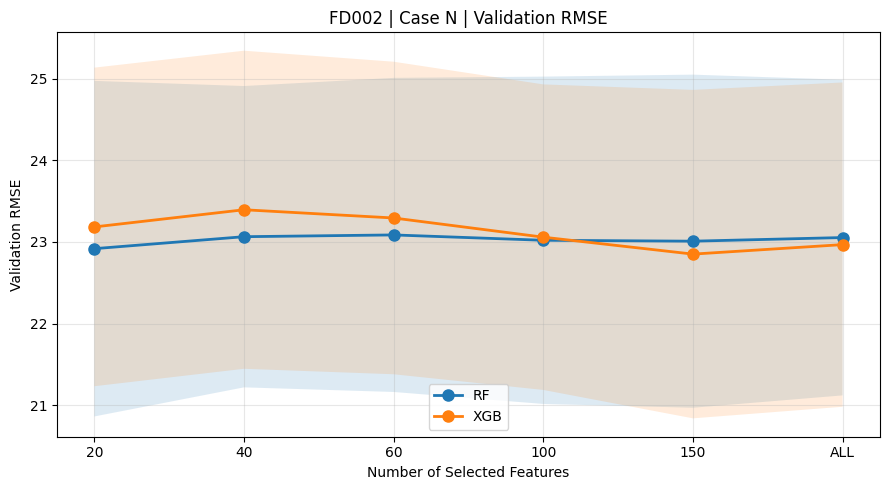

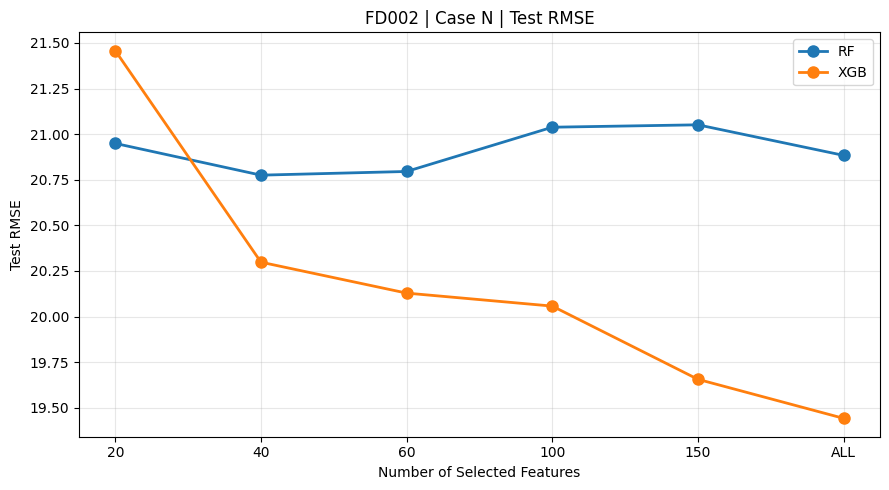

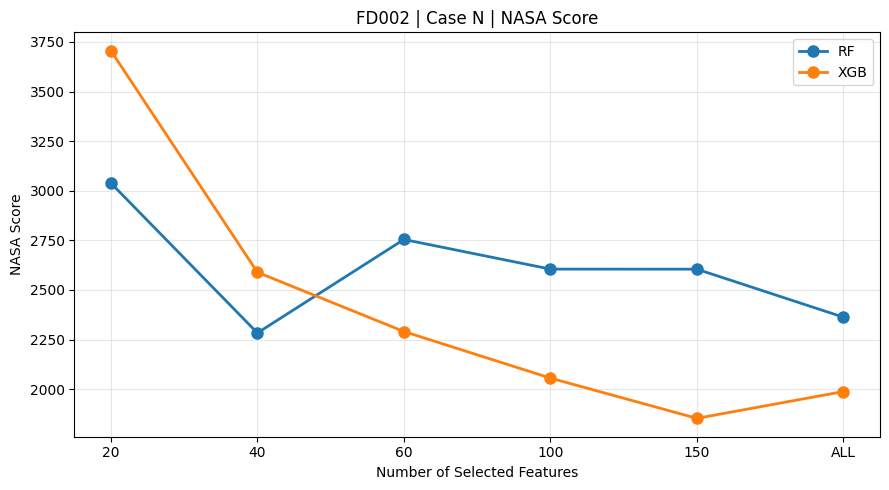

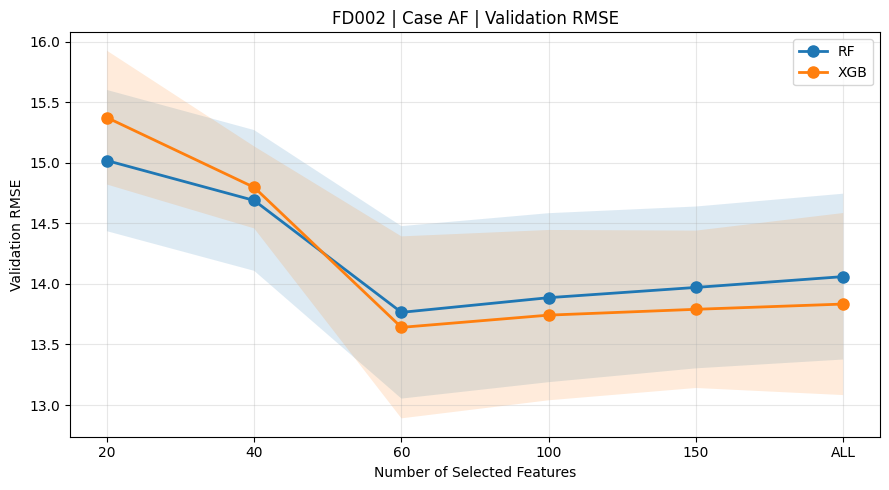

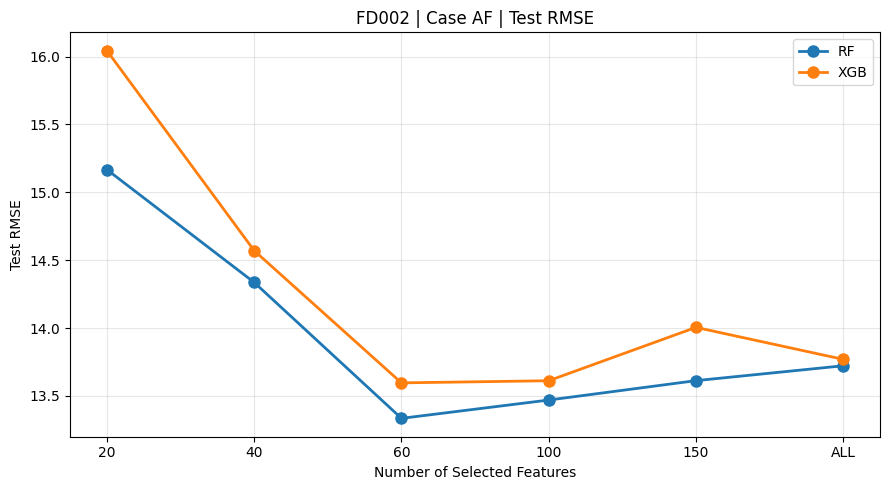

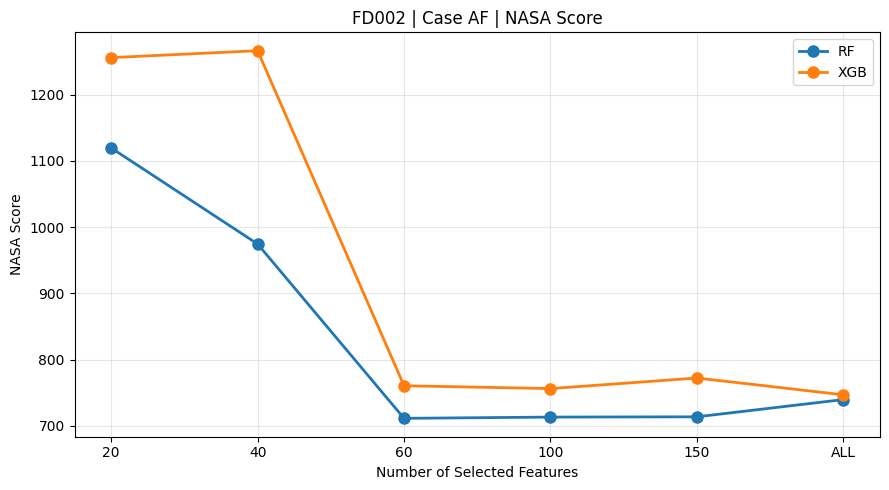

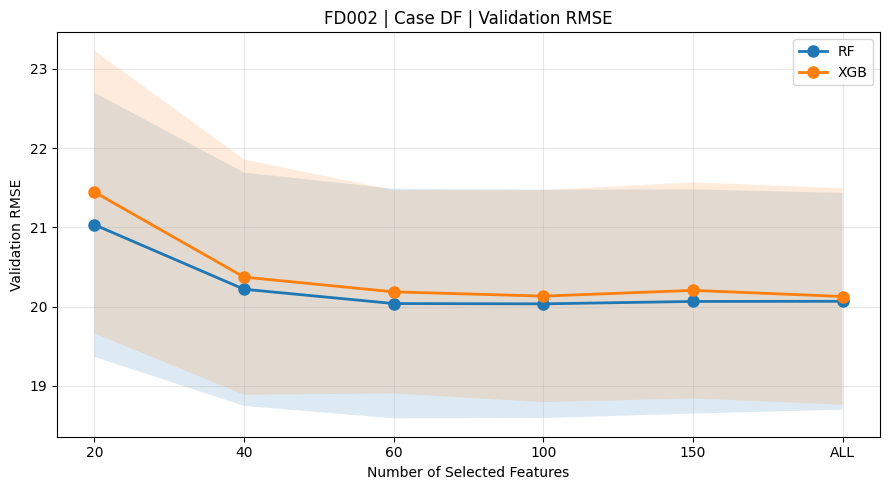

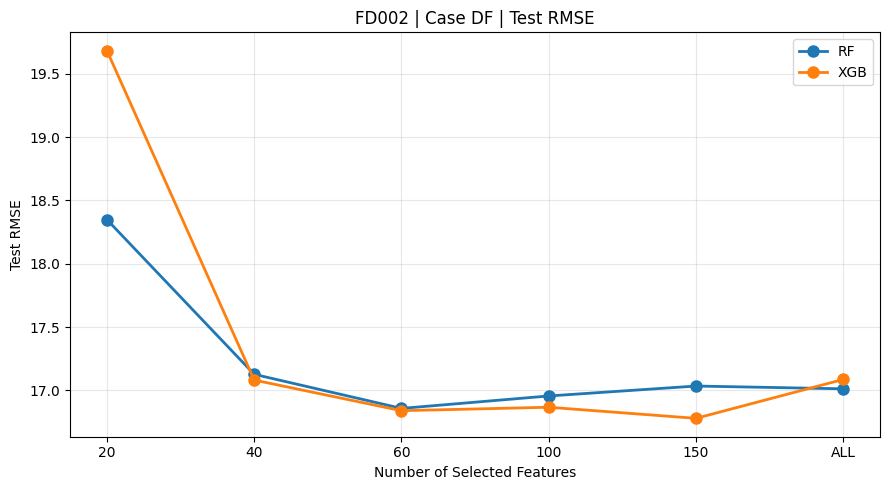

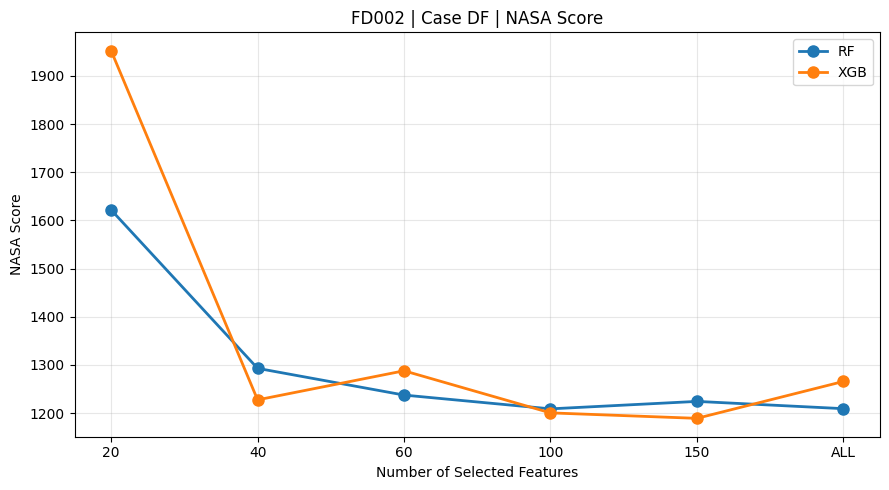

In [17]:
# ============================================================
# FD002: FEATURE BUDGET COMPARISON
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "/kaggle/working/feature_selection_summary_FD002.csv"
)

budgets = ['20', '40', "60", "100", "150", "ALL"]
models = ["RF", "XGB"]
cases = ["N", "AF", "DF"]

metrics = [
    ("val_rmse_mean", "val_rmse_sd", "Validation RMSE"),
    ("test_rmse", None, "Test RMSE"),
    ("test_nasa_score", None, "NASA Score")
]

for case in cases:

    case_df = df[df["case"] == case]

    for metric, error, title in metrics:

        fig, ax = plt.subplots(figsize=(9, 5))

        for model in models:

            data = (
                case_df[case_df["model"] == model]
                .set_index("budget")
                .reindex(budgets)
            )

            y = data[metric].values
            x = np.arange(len(budgets))

            ax.plot(
                x, y,
                marker="o",
                linewidth=2,
                markersize=8,
                label=model
            )

            if error is not None:
                sd = data[error].values
                ax.fill_between(
                    x, y - sd, y + sd,
                    alpha=0.15
                )

        ax.set_xticks(range(len(budgets)))
        ax.set_xticklabels(budgets)

        ax.set_xlabel("Number of Selected Features")
        ax.set_ylabel(title)
        ax.set_title(f"FD002 | Case {case} | {title}")

        ax.grid(alpha=0.3)
        ax.legend()
        plt.tight_layout()
        plt.show()